# A2 – Seasons (RQ1)
**Name:** _[your name]_  ·  dataset I'm responsible for: Cadre Harmonisé

**My question:** If food is most expensive in the summer (the lean season), is that also when hunger is highest?

"Hunger" here = % of people in Cadre Harmonisé **phase 3 or worse** (crisis, emergency, famine).

Plan (I make 3 charts and then pick 2 for the report):
1. **Heatmap** – in which months is each food expensive, and is hunger highest in the same months?
2. **Top 10 vs top 10** – are the regions with the biggest summer price jump also the hungriest regions?
3. **Year by year** – does this happen every year, and is it getting worse?

I use the cleaned files from our team script (`clean/`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pathlib import Path

# the notebook is in a2_seasons/, data is one folder up
folder = Path("..") if Path("../clean").exists() else Path(".")

prices = pd.read_csv(folder / "clean/market_month_full.csv")
ch = pd.read_csv(folder / "clean/ch_region_season.csv")

print("prices:", prices.shape)
prices.head()

prices: (102811, 33)


,country,iso3,region_code,region_name,district,market,market_id,latitude,longitude,food,...,conflict_events,conflict_deaths,rain_mm,rain_anomaly_mm,prev_rainy_season_pct_normal,ch_share_phase35,ch_season,fao_food_index,fao_cereals_index,fao_oils_index
0,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,0.0,0.0,107.4,0.0,Jan-May 2015,101.0,105.9,95.00
1,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,0.3,-0.0,107.4,0.0,Jan-May 2015,98.7,101.6,95.18
2,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,5.4,-17.8,107.4,0.0,Jan-May 2015,94.6,98.2,91.87
3,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,31.0,-29.9,107.4,0.0,Jan-May 2015,95.0,95.7,94.49
4,Burkina Faso,BFA,BF13,Centre,KADIOGO,Gounghin,3376,12.36,-1.55,cowpeas,...,0,0,230.3,36.2,107.4,NaN,NaN,93.8,98.9,90.43


And my dataset, the Cadre Harmonisé, already grouped by region. One row = one region, one year, one season.
`phase1`...`phase5` are numbers of **people**, `share_phase35` = % of people in phase 3 or worse.

In [2]:
print("cadre harmonise:", ch.shape)
ch.head()

cadre harmonise: (1921, 19)


,region_code,reference_year,reference_label,chtype,population,population_analysed,worst_district_phase,n_areas,phase1,phase2,phase3,phase4,phase5,phase35,share_phase35,pct_population_analysed,country,iso3,region_name
0,BF13,2015,Jan-May,current,2519055.0,2519055.0,1.0,1,2485175.0,33880.0,0.0,0.0,0.0,0.0,0.0,100.0,Burkina Faso,BFA,Centre
1,BF13,2015,Jun-Aug,projected,2519055.0,2519055.0,1.0,1,2493864.0,25191.0,0.0,0.0,0.0,0.0,0.0,100.0,Burkina Faso,BFA,Centre
2,BF13,2015,Sep-Dec,current,2623517.0,2623517.0,1.0,1,2439871.0,183646.0,0.0,0.0,0.0,0.0,0.0,100.0,Burkina Faso,BFA,Centre
3,BF13,2016,Jan-May,current,2623517.0,2623517.0,1.0,1,2571046.0,52470.0,0.0,0.0,0.0,0.0,0.0,100.0,Burkina Faso,BFA,Centre
4,BF13,2016,Jun-Aug,projected,2623517.0,2623517.0,1.0,1,2492341.0,131176.0,0.0,0.0,0.0,0.0,0.0,100.0,Burkina Faso,BFA,Centre


In [3]:
# one region, so you can see the 3 seasons per year
ch[ch["region_name"] == "Diffa"][["region_name", "reference_year", "reference_label", "chtype",
                                  "population_analysed", "phase35", "share_phase35"]].head(6)

,region_name,reference_year,reference_label,chtype,population_analysed,phase35,share_phase35
664,Diffa,2015,Jan-May,current,652411.0,147911.0,22.67
665,Diffa,2015,Jun-Aug,projected,652411.0,165564.0,25.38
666,Diffa,2015,Sep-Dec,current,684308.0,147563.0,21.56
667,Diffa,2016,Jan-May,current,619273.0,159620.0,25.78
668,Diffa,2016,Jun-Aug,projected,619273.0,104108.0,16.81
669,Diffa,2016,Sep-Dec,current,619849.0,66202.0,10.68


## Step 1: clean up a bit

- remove the 12 outliers that the cleaning script flagged
- make a "series" id = one market + one food (each market sells several foods)

In [4]:
prices = prices[prices["outlier_flag"] == False].copy()
prices["series"] = prices["market_id"].astype(str) + "_" + prices["food"]

print("rows:", len(prices))
print("series:", prices["series"].nunique())
print("markets:", prices["market_id"].nunique())

# how many series per country and food
pd.crosstab(prices["country"], prices["food"], values=prices["series"], aggfunc="nunique").fillna(0)

rows: 102799
series: 950
markets: 252


food,cowpeas,maize,millet,rice_imported,rice_local,sorghum
country,,,,,,
Burkina Faso,60.0,54.0,61.0,13.0,24.0,58.0
Chad,0.0,12.0,23.0,6.0,1.0,20.0
Mali,38.0,45.0,58.0,48.0,48.0,52.0
Niger,0.0,47.0,53.0,53.0,0.0,48.0
Senegal,0.0,19.0,40.0,39.0,16.0,14.0


## Step 2: seasonal index

Prices are very different between foods and markets, and they also go up over the years (inflation, 2022...).
To only see the **pattern inside a year**, I divide every price by the average price of the same market + food in that same year, times 100.

So 100 = normal for that year, 107 = 7% more expensive than usual.

I only use market-years with at least 10 months of prices, otherwise the yearly average is not reliable.

In [5]:
# how many months each market-year has, and its average price
prices["n_months"] = prices.groupby(["series", "year"])["price_lcu"].transform("count")
prices["year_avg"] = prices.groupby(["series", "year"])["price_lcu"].transform("mean")

seasonal = prices[prices["n_months"] >= 10].copy()
seasonal["index"] = seasonal["price_lcu"] / seasonal["year_avg"] * 100

print("rows used:", len(seasonal))
print("market-years used:", seasonal.groupby(["series", "year"]).ngroups)
seasonal[["market", "food", "month", "price_lcu", "year_avg", "index"]].head()

rows used: 92313
market-years used: 7963


,market,food,month,price_lcu,year_avg,index
0,Gounghin,cowpeas,2015-01,250.0,281.8,88.715401
1,Gounghin,cowpeas,2015-02,250.0,281.8,88.715401
2,Gounghin,cowpeas,2015-04,265.0,281.8,94.038325
3,Gounghin,cowpeas,2015-05,266.0,281.8,94.393187
4,Gounghin,cowpeas,2015-07,303.0,281.8,107.523066


In [6]:
# median index per food and month (median so a few weird markets don't matter much)
heat = seasonal.pivot_table(index="food", columns="month_of_year", values="index", aggfunc="median")

# sort foods by how much they move during the year
heat["range"] = heat.max(axis=1) - heat.min(axis=1)
heat = heat.sort_values("range", ascending=False).drop(columns="range")
heat.round(1)

month_of_year,1,2,3,4,5,6,7,8,9,10,11,12
food,,,,,,,,,,,,
sorghum,90.7,93.2,96.0,98.7,100.7,102.2,104.3,107.5,107.2,103.1,98.1,94.8
maize,91.5,93.2,95.3,98.9,101.0,102.4,105.0,107.6,107.1,100.3,94.9,94.6
cowpeas,92.3,98.2,100.0,101.5,102.1,103.3,104.8,107.3,107.0,98.3,91.4,94.7
millet,91.9,93.8,95.3,98.4,100.7,102.1,104.3,106.8,106.2,100.6,98.3,95.6
rice_local,95.8,96.7,97.6,98.7,100.0,100.0,100.3,102.2,103.5,103.0,100.4,99.9
rice_imported,99.1,99.7,99.8,99.9,100.0,100.0,100.0,100.0,100.2,100.1,100.0,100.0


Millet, sorghum, maize and cowpeas are lowest in January (~92) and highest in August/September (~107).
Imported rice basically doesn't change. Local rice goes up a bit but later (Sep/Oct).

Quick check if this is the same in every country (millet only):

In [7]:
millet_country = seasonal[seasonal["food"] == "millet"].pivot_table(
    index="country", columns="month_of_year", values="index", aggfunc="median")
millet_country.round(1)

month_of_year,1,2,3,4,5,6,7,8,9,10,11,12
country,,,,,,,,,,,,
Burkina Faso,91.2,92.7,95.7,99.6,100.8,100.9,102.0,105.0,105.5,103.2,102.1,97.3
Chad,92.4,93.3,94.0,96.3,102.5,106.2,107.0,108.2,106.8,100.7,94.6,91.5
Mali,91.1,93.6,94.3,96.9,99.6,100.8,102.6,104.8,106.8,105.5,102.7,99.1
Niger,89.5,93.8,96.4,100.7,103.8,106.7,111.7,114.9,105.8,90.5,89.2,91.1
Senegal,97.1,96.7,95.8,96.3,97.2,99.5,102.4,104.0,107.0,103.8,98.0,96.2


Yes – every country peaks in August or September. Niger has the biggest peak (115 in August).

## Step 3: how big is the lean-season jump?

For every market-year: average price in **Jul–Sep** compared to the average in **Jan–Mar** (right after the harvest).
I need at least 2 of the 3 months in both windows.

In [8]:
jan_mar = seasonal[seasonal["month_of_year"].isin([1, 2, 3])]
jul_sep = seasonal[seasonal["month_of_year"].isin([7, 8, 9])]

low = jan_mar.groupby(["series", "year"])["price_lcu"].agg(["mean", "count"])
high = jul_sep.groupby(["series", "year"])["price_lcu"].agg(["mean", "count"])

both = low.join(high, lsuffix="_low", rsuffix="_high", how="inner")
both = both[(both["count_low"] >= 2) & (both["count_high"] >= 2)]
both["rise_pct"] = (both["mean_high"] / both["mean_low"] - 1) * 100
display(both.head())

# add food / country / region back
info = seasonal.drop_duplicates(["series", "year"]).set_index(["series", "year"])[["food", "country", "region_code", "region_name"]]
rise = both[["rise_pct"]].join(info).reset_index()
print("market-years with a rise:", len(rise))
rise.head()

mean_low  count_low   mean_high  count_high   rise_pct
series       year                                                          
1043_cowpeas 2015  377.500000          2  370.000000           3  -1.986755
             2016  298.000000          2  367.000000           3  23.154362
             2017  309.000000          3  391.000000           3  26.537217
             2018  383.333333          3  411.666667           3   7.391304
             2019  361.000000          3  288.000000           3 -20.221607

market-years with a rise:

 7873


,series,year,rise_pct,food,country,region_code,region_name
0,1043_cowpeas,2015,-1.986755,cowpeas,Burkina Faso,BF52,Est
1,1043_cowpeas,2016,23.154362,cowpeas,Burkina Faso,BF52,Est
2,1043_cowpeas,2017,26.537217,cowpeas,Burkina Faso,BF52,Est
3,1043_cowpeas,2018,7.391304,cowpeas,Burkina Faso,BF52,Est
4,1043_cowpeas,2019,-20.221607,cowpeas,Burkina Faso,BF52,Est


In [9]:
summary = rise.groupby("food")["rise_pct"].median().sort_values(ascending=False).to_frame("median rise %")

# what this means for a cash transfer: if the price is r% higher, the same money buys 1 - 1/(1+r) less
summary["same money buys % less"] = 100 - 100 / (1 + summary["median rise %"] / 100)
summary.round(1)

,median rise %,same money buys % less
food,,
maize,15.7,13.6
sorghum,15.3,13.3
millet,14.3,12.5
cowpeas,9.6,8.7
rice_local,6.5,6.1
rice_imported,0.4,0.4


Grains are around **+15%** in the lean season. Careful: that does not mean 15% less food – it's about **13% less**
(I first got this wrong).

## Step 4: Cadre Harmonisé

Now the hunger side. For each season I take: people in phase 3–5 / population analysed (all 5 countries together, 2015–2024).

Things to know about this dataset:
- Jan–May and Sep–Dec are "current" analyses, but **Jun–Aug is only ever a projection**
- I remove the 13 "current Jun–Aug" rows (only Burkina Faso June 2020), so all three seasons are the same kind every year

In [10]:
ch = ch[(ch["reference_year"] >= 2015) & (ch["reference_year"] <= 2024)]
ch = ch[~((ch["chtype"] == "current") & (ch["reference_label"] == "Jun-Aug"))]
print("rows left:", len(ch))
display(ch[["region_name", "reference_year", "reference_label", "chtype", "share_phase35"]].head())

ch_seasons = ch.groupby(["chtype", "reference_label"])[["phase35", "population_analysed"]].sum()
ch_seasons["pct_phase3plus"] = ch_seasons["phase35"] / ch_seasons["population_analysed"] * 100
ch_seasons.round(1)

rows left: 1908


,region_name,reference_year,reference_label,chtype,share_phase35
0,Centre,2015,Jan-May,current,0.0
1,Centre,2015,Jun-Aug,projected,0.0
2,Centre,2015,Sep-Dec,current,0.0
3,Centre,2016,Jan-May,current,0.0
4,Centre,2016,Jun-Aug,projected,0.0


phase35  population_analysed  pct_phase3plus
chtype    reference_label                                                 
current   Jan-May          40968799.0          859328523.4             4.8
          Sep-Dec          40589529.0          909722626.0             4.5
projected Jun-Aug          66099568.0          886152491.4             7.5

In [11]:
# same thing per year, to see if the lean season is always the worst
per_year = ch.groupby(["reference_year", "reference_label"])[["phase35", "population_analysed"]].sum()
per_year["pct"] = per_year["phase35"] / per_year["population_analysed"] * 100
per_year = per_year["pct"].unstack()[["Jan-May", "Jun-Aug", "Sep-Dec"]]

print("Jun-Aug higher than Jan-May every year?", (per_year["Jun-Aug"] > per_year["Jan-May"]).all())
per_year.round(1)

Jun-Aug higher than Jan-May every year? True


reference_label,Jan-May,Jun-Aug,Sep-Dec
reference_year,,,
2015,2.9,5.0,1.6
2016,3.1,4.4,1.8
2017,2.5,4.8,1.7
2018,3.3,5.1,1.6
2019,2.2,3.8,4.5
2020,5.1,6.9,4.9
2021,6.3,8.9,6.6
2022,9.2,12.3,6.3
2023,6.3,10.2,7.1


The lean season (Jun–Aug) is higher than Jan–May in **every** year. Also crisis levels roughly doubled after 2019.

Some seasons are missing (Mali Jan–May 2022, Niger Jan–May 2024, Burkina Faso Sep–Dec 2024). To check that this doesn't
change the result, I redo it only with region-years that have all three seasons:

In [12]:
tmp = ch.dropna(subset=["phase35"])
seasons_per_region_year = tmp.groupby(["region_code", "reference_year"])["reference_label"].nunique()
complete = seasons_per_region_year[seasons_per_region_year == 3].index
print("complete region-years:", len(complete))

tmp = tmp.set_index(["region_code", "reference_year"]).loc[complete]
check = tmp.groupby("reference_label")[["phase35", "population_analysed"]].sum()
(check["phase35"] / check["population_analysed"] * 100).round(1)

complete region-years: 591


reference_label
Jan-May    4.7
Jun-Aug    7.2
Sep-Dec    4.4
dtype: float64

Almost the same (4.7 / 7.2 / 4.4 instead of 4.8 / 7.5 / 4.5), so the missing seasons don't change the story.

## Chart 1: heatmap

My first version had a number in every cell and a lot of labels – too much to read. This time I want it **clean**: the colour tells the story, and only a few numbers are written.

**Why these colours and styles:**
- **Red–white–blue (`RdBu_r`) for prices.** The index has a natural middle: 100 = normal for that year. A *diverging* colour map fits that: white = normal, red = more expensive, blue = cheaper. I picked red for "expensive" because red already means "warning" for most people.
- **Scale from 88 to 112, the same distance on both sides of 100.** This way white is exactly 100, and "8% cheaper" looks as strong as "8% more expensive". If the scale wasn't centred, one side would look more dramatic than it is.
- **Only the lowest and highest month of each food has a number.** That's the important part (how low → how high). The other cells you can read from the colour.
- **Hunger strip on top in grey (`Greys`).** I first had it in blue, but blue already means "cheap" in the heatmap, so it was confusing. Grey has no meaning here, so the only colours in the chart are about prices. Darker grey = more people in crisis, so the darkest block (Jun–Aug) jumps out.
- **The strip uses the same month axis as the heatmap.** You can look straight down from the dark grey block to the red cells and see they line up.
- **"(forecast)"** under 7.5% because the Cadre Harmonisé only ever *predicts* Jun–Aug, it doesn't measure it.
- **Foods sorted by how much they change in a year**, so the foods with a strong season are on top and the two rices (almost no season) at the bottom.
- **No grid lines, no box around the heatmap**, the cells are already a grid.
- **The title says the finding**, not just "Heatmap of prices", so you know what to look for.

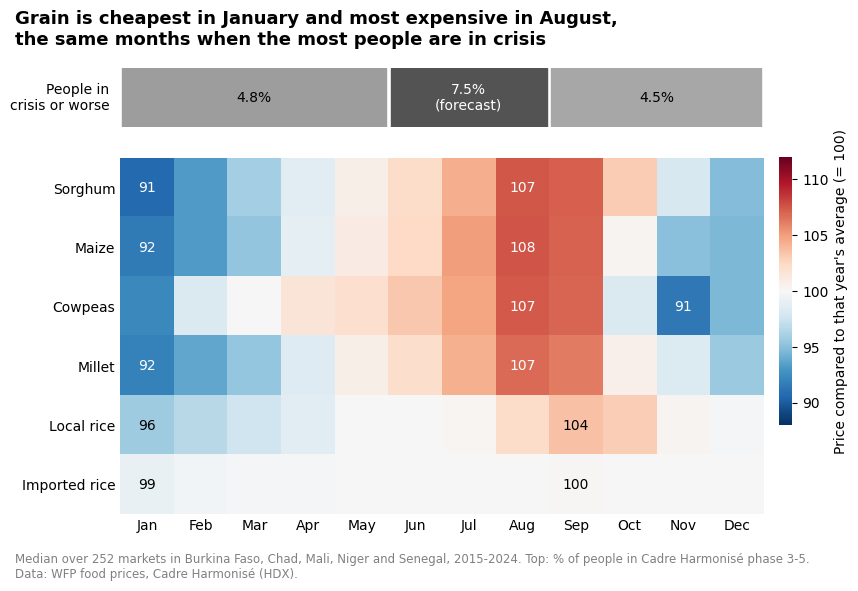

In [13]:
food_names = {"millet": "Millet", "sorghum": "Sorghum", "maize": "Maize", "cowpeas": "Cowpeas",
              "rice_local": "Local rice", "rice_imported": "Imported rice"}
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

ch_pct = ch_seasons["pct_phase3plus"]
hunger = [ch_pct["current", "Jan-May"], ch_pct["projected", "Jun-Aug"], ch_pct["current", "Sep-Dec"]]
starts = [-0.5, 4.5, 7.5]   # Jan-May, Jun-Aug, Sep-Dec in heatmap coordinates
ends = [4.5, 7.5, 11.5]
extra = ["", "\n(forecast)", ""]

fig, (ax_top, ax) = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True,
                                 gridspec_kw={"height_ratios": [1, 6], "hspace": 0.15})

# --- top: hunger per season, in grey ---
for start, end, value, txt in zip(starts, ends, hunger, extra):
    ax_top.axvspan(start + 0.04, end - 0.04, color=plt.cm.Greys(value / 10))
    ax_top.text((start + end) / 2, 0.5, f"{value:.1f}%{txt}", ha="center", va="center", fontsize=10,
                color="white" if value > 6 else "black")
ax_top.set_ylim(0, 1)
ax_top.axis("off")
ax_top.text(-0.7, 0.5, "People in\ncrisis or worse", ha="right", va="center", fontsize=10)

# --- heatmap ---
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=88, vmax=112, aspect="auto")
ax.set_xticks(range(12))
ax.set_xticklabels(months)
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([food_names[f] for f in heat.index])
ax.tick_params(length=0)
for side in ["top", "right", "bottom", "left"]:
    ax.spines[side].set_visible(False)

# only write the lowest and the highest month of each food
for i in range(len(heat)):
    row = heat.values[i]
    for j in [row.argmin(), row.argmax()]:
        ax.text(j, i, f"{row[j]:.0f}", ha="center", va="center", fontsize=10,
                color="white" if abs(row[j] - 100) > 5 else "black")

cbar = fig.colorbar(im, ax=[ax_top, ax], shrink=0.6, pad=0.02)
cbar.set_label("Price compared to that year's average (= 100)")
cbar.outline.set_visible(False)

fig.suptitle("Grain is cheapest in January and most expensive in August,\n"
             "the same months when the most people are in crisis",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
n_markets = seasonal["market_id"].nunique()
fig.text(0.02, 0.0, f"Median over {n_markets} markets in Burkina Faso, Chad, Mali, Niger and Senegal, 2015-2024. "
         "Top: % of people in Cadre Harmonisé phase 3-5.\nData: WFP food prices, Cadre Harmonisé (HDX).",
         fontsize=8.5, color="grey")
plt.savefig("fig1_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 5: regions

Now only millet (most markets, all 5 countries). Per region I take the median rise over all its market-years.
I drop regions with fewer than 10 millet market-years (too little data).

For the Cadre Harmonisé I use the average projected Jun–Aug % in phase 3+ for each region.

In [14]:
millet = rise[rise["food"] == "millet"]

regions = millet.groupby(["country", "region_code", "region_name"]).agg(
    median=("rise_pct", "median"),
    n=("rise_pct", "count"),
    markets=("series", "nunique")).reset_index()
display(regions.head())

print("dropped:", list(regions.loc[regions["n"] < 10, "region_name"]))
regions = regions[regions["n"] >= 10]

lean = ch[(ch["chtype"] == "projected") & (ch["reference_label"] == "Jun-Aug")]
ch_region = lean.groupby("region_code")["share_phase35"].mean().rename("ch_lean")
regions = regions.merge(ch_region, on="region_code", how="left")

rho, p = spearmanr(regions["median"], regions["ch_lean"])
print(f"{len(regions)} regions, Spearman rho = {rho:.2f}, p = {p:.3f}")
regions.sort_values("median", ascending=False).round(1).head(10)

,country,region_code,region_name,median,n,markets
0,Burkina Faso,BF13,Centre,3.612285,20,2
1,Burkina Faso,BF46,Boucle du Mouhoun,12.539272,88,9
2,Burkina Faso,BF47,Cascades,7.902025,20,2
3,Burkina Faso,BF48,Centre-Est,10.618280,49,5
4,Burkina Faso,BF49,Centre-Nord,11.185682,39,4


dropped: ['Lac', 'Logone Occidental', 'Logone Oriental', 'Moyen-Chari', "N'Djamena", 'Barh-El-Gazel', 'Kedougou', 'Sedhiou']
50 regions, Spearman rho = 0.26, p = 0.065


,country,region_code,region_name,median,n,markets,ch_lean
31,Niger,NE002,Diffa,25.3,38,4,21.3
32,Niger,NE003,Dosso,25.0,48,5,6.4
34,Niger,NE005,Tahoua,22.1,58,8,8.4
20,Chad,TCD17,Wadi Fira,21.8,18,2,16.9
48,Senegal,SN13,Thies,21.6,33,4,3.1
36,Niger,NE007,Zinder,21.1,66,8,7.4
18,Chad,TCD14,Ouaddai,20.9,17,2,13.9
21,Chad,TCD21,Sila,20.1,15,2,12.1
35,Niger,NE006,Tillaberi,19.7,82,11,14.5
15,Chad,TCD04,Guera,19.1,10,1,11.9


Hmm, rho = 0.26 is **weak** (and p > 0.05). I expected the regions with the biggest price jump to also have the most
hunger, but that's not really true. Quick scatter to see why (just for me, not for the report – it looks too messy):

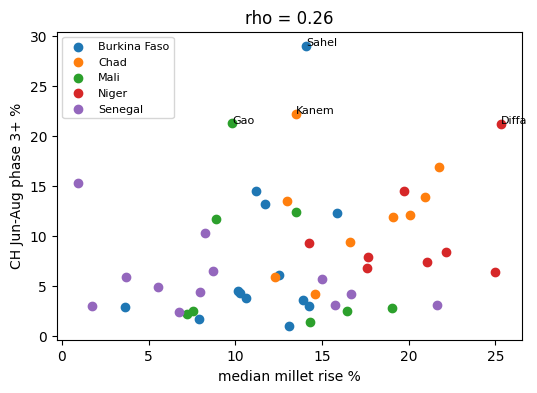

In [15]:
plt.figure(figsize=(6, 4))
for country in regions["country"].unique():
    d = regions[regions["country"] == country]
    plt.scatter(d["median"], d["ch_lean"], label=country)
for _, r in regions[regions["ch_lean"] > 18].iterrows():
    plt.annotate(r["region_name"], (r["median"], r["ch_lean"]), fontsize=8)
plt.xlabel("median millet rise %")
plt.ylabel("CH Jun-Aug phase 3+ %")
plt.legend(fontsize=8)
plt.title(f"rho = {rho:.2f}")
plt.show()

Sahel (Burkina Faso), Gao (Mali) and Kanem (Chad) have a lot of people in crisis but only a normal price jump.
These are conflict areas, so maybe there prices are high all year, not only in the lean season
(that's more for the conflict question – I can't prove it with this chart).

A simpler way to show this: take the **10 regions with the biggest price jump** and the **10 hungriest regions**, and see how many are in both lists.

In [16]:
abbr = {"Niger": "NE", "Chad": "TD", "Burkina Faso": "BF", "Mali": "ML", "Senegal": "SN"}
regions["label"] = regions["region_name"] + " (" + regions["country"].map(abbr) + ")"

top_price = set(regions.nlargest(10, "median")["region_code"])
top_hunger = set(regions.nlargest(10, "ch_lean")["region_code"])
in_both = top_price & top_hunger

print("in both top 10 lists:", len(in_both))
regions[regions["region_code"].isin(in_both)][["label", "median", "ch_lean"]].round(1)

in both top 10 lists: 4


,label,median,ch_lean
18,Ouaddai (TD),20.9,13.9
20,Wadi Fira (TD),21.8,16.9
31,Diffa (NE),25.3,21.3
35,Tillaberi (NE),19.7,14.5


Only 4 regions are in both lists. (I first tried "top 10 vs **bottom** 10 price jump", but that made the link look weaker than it is,
because the bottom-10 regions are also not very hungry. Top 10 vs top 10 is the fair comparison.)

## Chart 2: top 10 vs top 10

**Why these colours and styles:**
- **Bars**, because I compare amounts (%) between regions, and length is the easiest thing to compare.
- **Two bar charts back to back with the region names in the middle**, so you read one row = one region: price jump on the left, hunger on the right. Two different units (price % and people %) never share one axis.
- **Red for the price jump** – the same red as "expensive" in the heatmap, so the two charts use colours the same way.
- **Dark grey for hunger** – again the same as the hunger strip in the heatmap.
- **Dark bar = this region is in that top 10, light bar = it's not.** So without reading numbers you can see which rows are dark on both sides.
- **Bold name = in both top 10 lists**, so the 4 overlap regions pop out.
- **Sorted by price jump**, so the top half are the "big jump" regions and you can see that many of them have short (light) hunger bars.
- **The number is written at the end of each bar**, so I removed the axes completely – less clutter.
- **Country as a short code** (NE, TD…) to keep the names short; the codes are explained at the bottom.

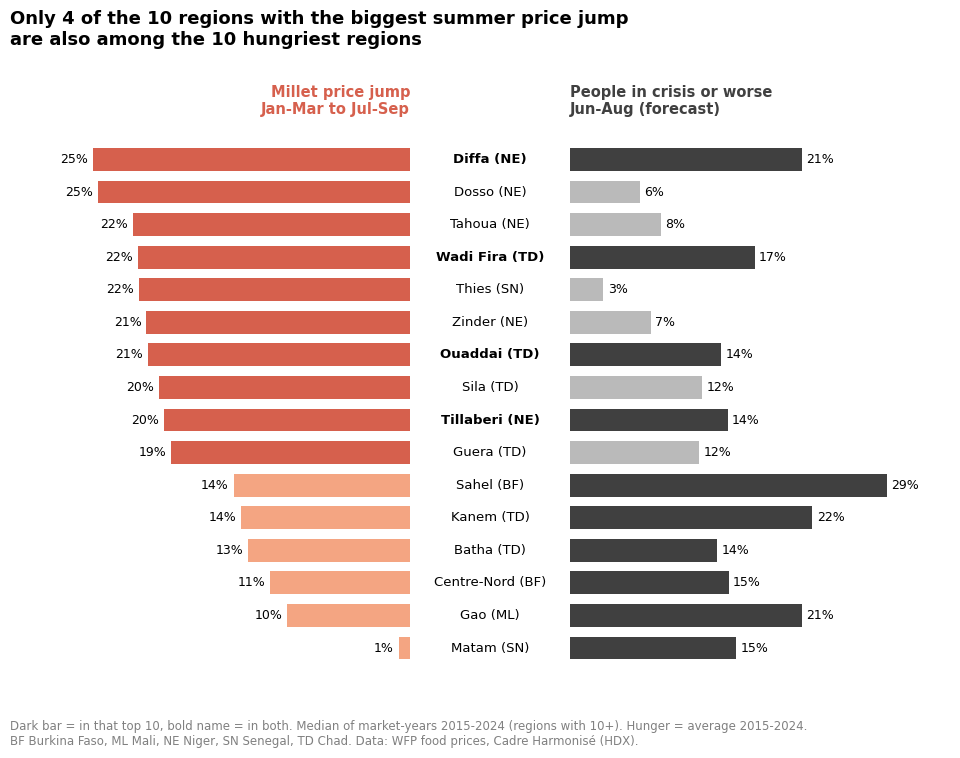

In [17]:
show = regions[regions["region_code"].isin(top_price | top_hunger)].sort_values("median", ascending=False)
y = list(range(len(show)))[::-1]   # first row at the top

price_colors = ["#d6604d" if c in top_price else "#f4a582" for c in show["region_code"]]   # reds from RdBu
hunger_colors = ["#404040" if c in top_hunger else "#bababa" for c in show["region_code"]]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 7.5), sharey=True, gridspec_kw={"wspace": 0.42})
fig.subplots_adjust(top=0.83, bottom=0.08, left=0.04, right=0.96)

left.barh(y, show["median"], color=price_colors, height=0.7)
right.barh(y, show["ch_lean"], color=hunger_colors, height=0.7)
left.invert_xaxis()   # left bars grow to the left

for yi, (_, r) in zip(y, show.iterrows()):
    left.text(r["median"] + 0.4, yi, f"{r['median']:.0f}%", ha="right", va="center", fontsize=9)
    right.text(r["ch_lean"] + 0.4, yi, f"{r['ch_lean']:.0f}%", ha="left", va="center", fontsize=9)
    weight = "bold" if r["region_code"] in in_both else "normal"
    # region name in the gap between the two charts
    right.text(-0.21, yi, r["label"], ha="center", va="center", fontsize=9.5, fontweight=weight,
               transform=right.get_yaxis_transform())

left.set_xlim(show["median"].max() * 1.2, 0)
right.set_xlim(0, show["ch_lean"].max() * 1.2)
for a in [left, right]:
    a.set_xticks([])
    a.set_yticks([])
    for side in ["top", "right", "bottom", "left"]:
        a.spines[side].set_visible(False)

left.set_title("Millet price jump\nJan-Mar to Jul-Sep", loc="right", fontsize=10.5, fontweight="bold", color="#d6604d")
right.set_title("People in crisis or worse\nJun-Aug (forecast)", loc="left", fontsize=10.5, fontweight="bold", color="#404040")

fig.suptitle(f"Only {len(in_both)} of the 10 regions with the biggest summer price jump\n"
             "are also among the 10 hungriest regions", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.0, "Dark bar = in that top 10, bold name = in both. Median of market-years 2015-2024 (regions with 10+). "
         "Hunger = average 2015-2024.\nBF Burkina Faso, ML Mali, NE Niger, SN Senegal, TD Chad. "
         "Data: WFP food prices, Cadre Harmonisé (HDX).", fontsize=8.5, color="grey")
plt.savefig("fig2_top10.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 6: year by year

Everything so far is the average over 10 years. But is it the same **every** year? Median millet jump per year, next to the Cadre Harmonisé per season and year (`per_year` from Step 4).

In [18]:
year_rise = millet.groupby("year")["rise_pct"].median()
display(year_rise.round(1).to_frame("median millet jump %").T)

# in which years was Jun-Aug the worst of the 3 seasons?
lean_worst = per_year["Jun-Aug"] == per_year.max(axis=1)
print("years where Jun-Aug is the worst season:", lean_worst.sum(), "of", len(per_year))
print("years with a price jump > 0:", (year_rise > 0).sum(), "of", len(year_rise))

# getting worse?
print("Jun-Aug average 2015-19:", per_year.loc[2015:2019, "Jun-Aug"].mean().round(1),
      " 2020-24:", per_year.loc[2020:2024, "Jun-Aug"].mean().round(1))

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
median millet jump %,8.1,8.6,25.9,8.2,-2.4,25.2,9.8,34.2,2.2,35.8


years where Jun-Aug is the worst season: 9 of 10
years with a price jump > 0: 9 of 10
Jun-Aug average 2015-19: 4.6  2020-24: 9.8


9 of 10 years: prices jump in summer **and** Jun–Aug is the worst hunger season. The exception is 2019 for both. And the lean-season hunger roughly doubled after 2019.

## Chart 3: year by year

**Why these colours and styles:**
- **Two charts on top of each other with the same years below**, because price jump (%) and people in crisis (%) are different things – I don't want two y-axes in one chart, that's easy to misread.
- **Red bars for the price jump** – same red as the other charts = price.
- **Grey bars for hunger, dark grey for Jun–Aug** – same as the other charts = hunger, and the lean season is the darkest so you see it's the tallest almost every year. Jan–May and Sep–Dec are two light greys, because they're "the other seasons"; the legend and the order (before → during → after) tell them apart.
- **Numbers on top of the red bars**, because the jump changes a lot (2% to 36%) and that's an important message: the "average" jump is not a safe number to plan with.
- **One note on 2019**, the only year that doesn't fit, so nobody thinks I hid it.
- **Bars start at 0** (and the price chart shows the negative 2019 bar below 0), so the bar lengths are honest.
- **No top/right frame lines**, they don't add anything.

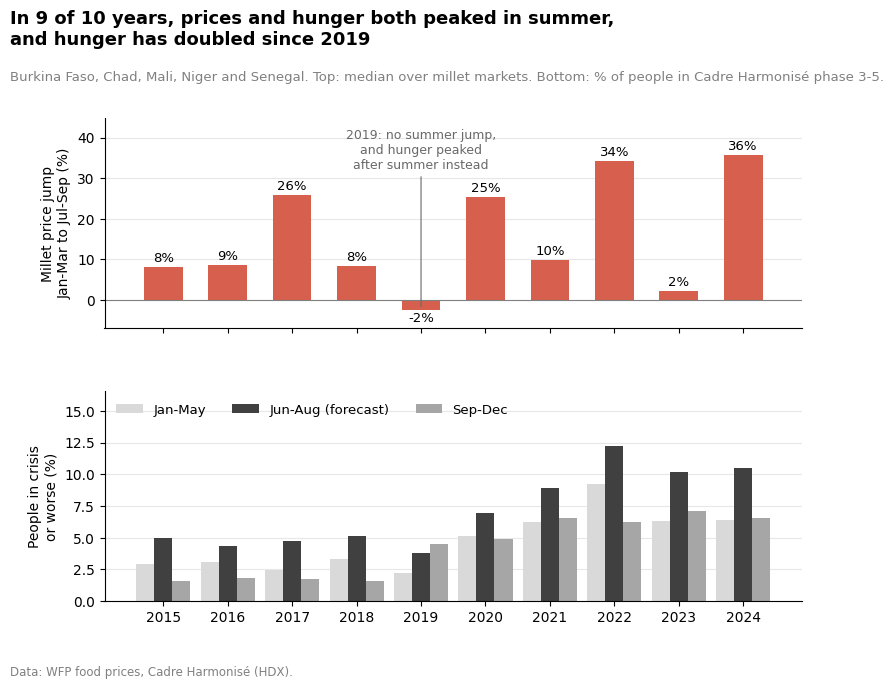

In [19]:
years = year_rise.index.values

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.8), sharex=True, gridspec_kw={"hspace": 0.3})
fig.subplots_adjust(top=0.82)

# --- top: millet price jump per year ---
a1.bar(years, year_rise.values, color="#d6604d", width=0.6)
for x, v in zip(years, year_rise.values):
    if v >= 0:
        a1.text(x, v + 0.6, f"{v:.0f}%", ha="center", va="bottom", fontsize=9.5)
    else:
        a1.text(x, v - 0.6, f"{v:.0f}%", ha="center", va="top", fontsize=9.5)
a1.axhline(0, color="grey", linewidth=0.8)
a1.set_ylim(-7, year_rise.max() * 1.25)
a1.set_ylabel("Millet price jump\nJan-Mar to Jul-Sep (%)")
a1.annotate("2019: no summer jump,\nand hunger peaked\nafter summer instead", xy=(2019, -2.4), xytext=(2019, 37),
            ha="center", va="center", fontsize=9, color="dimgrey",
            arrowprops=dict(arrowstyle="-", color="dimgrey", linewidth=0.8))

# --- bottom: hunger per season and year ---
w = 0.28
a2.bar(years - w, per_year.loc[years, "Jan-May"], width=w, color="#d9d9d9", label="Jan-May")
a2.bar(years, per_year.loc[years, "Jun-Aug"], width=w, color="#404040", label="Jun-Aug (forecast)")
a2.bar(years + w, per_year.loc[years, "Sep-Dec"], width=w, color="#a6a6a6", label="Sep-Dec")
a2.set_ylabel("People in crisis\nor worse (%)")
a2.set_xticks(years)
a2.set_ylim(0, per_year.loc[years].max().max() * 1.35)
a2.legend(frameon=False, ncol=3, fontsize=9.5, loc="upper left")

for a in [a1, a2]:
    a.grid(axis="y", alpha=0.3)
    a.set_axisbelow(True)
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)

fig.suptitle("In 9 of 10 years, prices and hunger both peaked in summer,\n"
             "and hunger has doubled since 2019", x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.875, "Burkina Faso, Chad, Mali, Niger and Senegal. Top: median over millet markets. "
         "Bottom: % of people in Cadre Harmonisé phase 3-5.", fontsize=9.5, color="grey")
fig.text(0.02, 0.0, "Data: WFP food prices, Cadre Harmonisé (HDX).", fontsize=8.5, color="grey")
plt.savefig("fig3_years.png", dpi=300, bbox_inches="tight")
plt.show()

## What I found

- Grains (millet, sorghum, maize) and cowpeas are about **15% more expensive in Jul–Sep** than in Jan–Mar → the same cash buys ~13% less food exactly in the lean season. Rice almost doesn't change.
- Hunger (Cadre Harmonisé phase 3+) is also highest in Jun–Aug: **7.5%** vs 4.8% and 4.5%.
- This happens in 9 of 10 years (not 2019), and lean-season hunger roughly doubled after 2019.
- But the regions with the biggest price jump are **not** always the hungriest: only 4 regions are in both top-10 lists (rho = 0.26, weak). Places like Sahel (BF) and Gao (ML) are very hungry with a normal price jump.

**Limitations:** Jun–Aug is only a forecast in the Cadre Harmonisé; HDX says the "current" periods are really Mar–May and Oct–Dec (the file calls them Jan–May and Sep–Dec); some regions have only 1–2 markets; prices are not adjusted for inflation; the top-10 cut-off is my choice (a different number would change the count a bit); correlation ≠ causation.

---
# Appendix: quick sketches (inspiration only, not for the report)

Plain matplotlib, no styling on purpose. Each one is a different chart type and a different small question.
They use the variables from above (`seasonal`, `rise`, `ch`), so the numbers are the same as in the main charts.

### Sketch 1 – small multiples of lines: is the price season the same in every country?

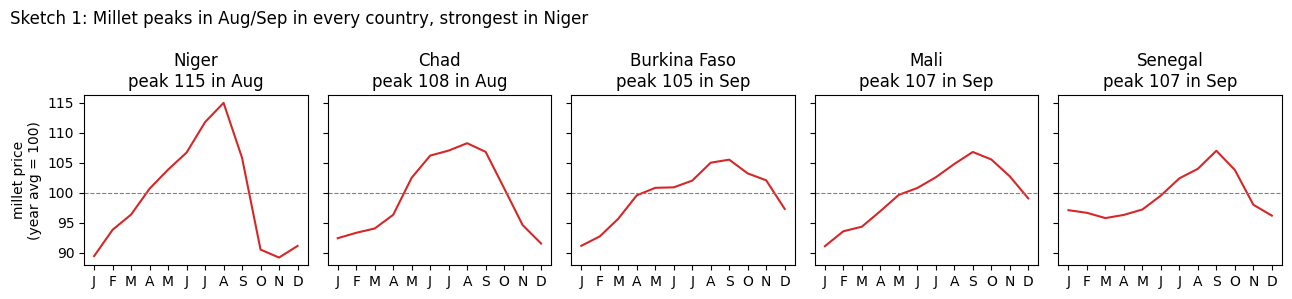

In [20]:
m = seasonal[seasonal["food"] == "millet"].pivot_table(
    index="month_of_year", columns="country", values="index", aggfunc="median")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharey=True)
for ax, c in zip(axes, ["Niger", "Chad", "Burkina Faso", "Mali", "Senegal"]):
    ax.plot(m.index, m[c], color="tab:red")
    ax.axhline(100, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(f"{c}\npeak {m[c].max():.0f} in {month_names[m[c].idxmax() - 1]}")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([n[0] for n in month_names])
axes[0].set_ylabel("millet price\n(year avg = 100)")
fig.suptitle("Sketch 1: Millet peaks in Aug/Sep in every country, strongest in Niger", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Sketch 2 – bars: which food rises most before the harvest?

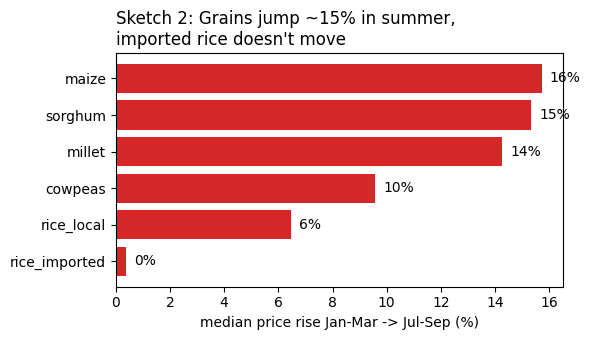

In [21]:
f = rise.groupby("food")["rise_pct"].median().sort_values()

plt.figure(figsize=(6, 3.5))
plt.barh(f.index, f.values, color="tab:red")
for i, v in enumerate(f.values):
    plt.text(v + 0.3, i, f"{v:.0f}%", va="center")
plt.xlabel("median price rise Jan-Mar -> Jul-Sep (%)")
plt.title("Sketch 2: Grains jump ~15% in summer,\nimported rice doesn't move", loc="left")
plt.tight_layout()
plt.show()

### Sketch 3 – 100% stacked bars: how does the mix of hunger phases change by season? (my dataset)

,phase1,phase2,phase3,phase4,phase5
reference_label,,,,,
Jan-May,78.7,16.6,4.5,0.3,0.0
Jun-Aug,71.6,21.0,6.9,0.6,0.0
Sep-Dec,79.1,16.5,4.2,0.2,0.0


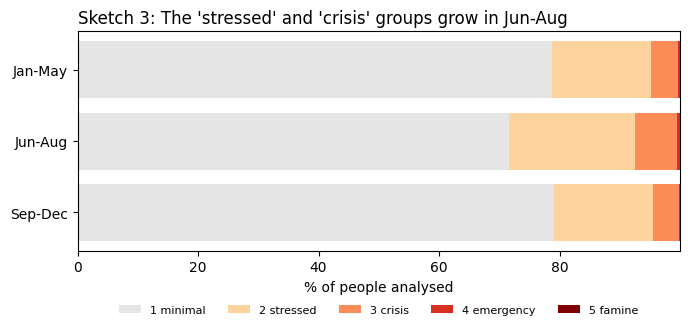

In [22]:
ph = ch.groupby("reference_label")[["phase1", "phase2", "phase3", "phase4", "phase5"]].sum()
ph = ph.div(ph.sum(axis=1), axis=0) * 100
ph = ph.loc[["Jan-May", "Jun-Aug", "Sep-Dec"]]
display(ph.round(1))

colors = ["#e5e5e5", "#fdd49e", "#fc8d59", "#d7301f", "#7f0000"]
names = ["1 minimal", "2 stressed", "3 crisis", "4 emergency", "5 famine"]
plt.figure(figsize=(7, 3.5))
left = 0
for col, c, n in zip(ph.columns, colors, names):
    plt.barh(ph.index, ph[col], left=left, color=c, label=n)
    left = left + ph[col]
plt.gca().invert_yaxis()
plt.xlabel("% of people analysed")
plt.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.title("Sketch 3: The 'stressed' and 'crisis' groups grow in Jun-Aug", loc="left")
plt.tight_layout()
plt.show()

### Sketch 4 – line per country: is lean-season hunger getting worse? (my dataset)

country,Burkina Faso,Chad,Mali,Niger,Senegal
reference_year,,,,,
2015,2.0,5.5,2.6,7.0,9.6
2016,2.5,8.2,2.3,5.8,4.2
2017,1.3,6.9,3.2,7.3,6.7
2018,4.7,7.2,4.9,3.8,6.0
2019,3.3,4.5,2.9,5.6,2.6
2020,NaN,6.9,6.5,9.1,4.6
2021,13.2,11.6,6.2,10.1,2.8
2022,16.1,13.3,8.5,17.7,5.0
2023,13.0,12.7,5.7,12.1,7.1


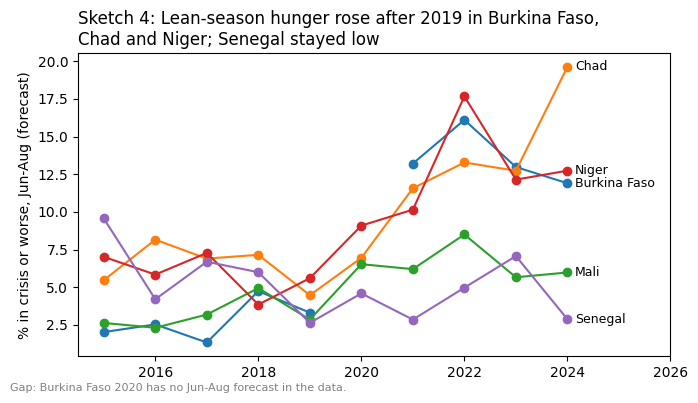

In [23]:
lean = ch[(ch["chtype"] == "projected") & (ch["reference_label"] == "Jun-Aug")]
t = lean.groupby(["reference_year", "country"])[["phase35", "population_analysed"]].sum()
t = (t["phase35"] / t["population_analysed"] * 100).unstack()
display(t.round(1))

plt.figure(figsize=(7, 4))
for c in t.columns:
    plt.plot(t.index, t[c], marker="o", label=c)
    plt.text(t.index[-1] + 0.15, t[c].iloc[-1], c, va="center", fontsize=9)
plt.ylabel("% in crisis or worse, Jun-Aug (forecast)")
plt.xlim(2014.5, 2026)
plt.title("Sketch 4: Lean-season hunger rose after 2019 in Burkina Faso,\nChad and Niger; Senegal stayed low", loc="left")
plt.figtext(0.01, 0.01, "Gap: Burkina Faso 2020 has no Jun-Aug forecast in the data.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

### Sketch 5 – box plots: how reliable is "the" seasonal jump?

share of market-years where millet got cheaper: 17.6 %


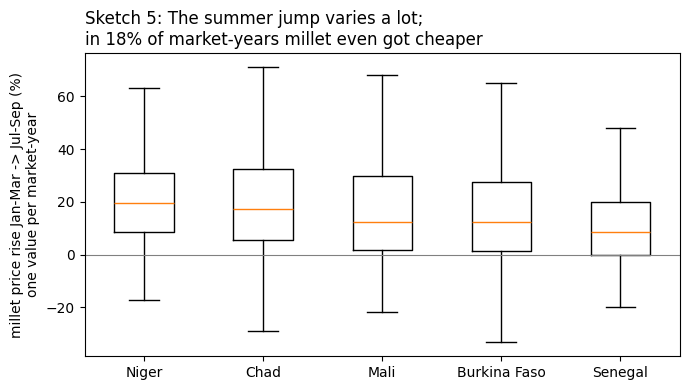

In [24]:
mb = rise[rise["food"] == "millet"]
order = mb.groupby("country")["rise_pct"].median().sort_values(ascending=False).index
print("share of market-years where millet got cheaper:", round((mb["rise_pct"] < 0).mean() * 100, 1), "%")

plt.figure(figsize=(7, 4))
plt.boxplot([mb[mb["country"] == c]["rise_pct"] for c in order], showfliers=False)
plt.xticks(range(1, len(order) + 1), order)
plt.axhline(0, color="grey", linewidth=0.8)
plt.ylabel("millet price rise Jan-Mar -> Jul-Sep (%)\none value per market-year")
plt.title("Sketch 5: The summer jump varies a lot;\nin 18% of market-years millet even got cheaper", loc="left")
plt.tight_layout()
plt.show()